# 06 · Is higher floor elevation associated with less damage?
**Venkat Repaka and Ritik Gaire · NFIP flood claims**

**Question:** are buildings with a higher floor linked to less damage?

"Freeboard" is the height of the lowest floor above the mapped base flood level. We start with the overall curve, find that it mixes very different foundation types, and then compare similar buildings step by step.

**Learning bridge:** clustering suggested that foundation matters. We now start with the overall elevation curve, discover its misleading mixture, compare similar buildings, and only then fit adjusted models. Each control is added to answer a specific concern.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from project_utils import *
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
df=load_joined()

### Step 1 · Check who is included
A complete-case curve can describe a selected subset. We compare availability before interpreting the elevation relationship.

In [2]:
has=df.elevationDifference.notna()
display(df.groupby(has).agg(claims=('id','size'),median_age=('building_age','median'),
    AE_share=('zone',lambda s:s.eq('AE').mean()),median_damage_ratio=('damage_ratio','median')))
d=df[df.elevationDifference.between(-6,10)&df.damage_ratio.notna()].copy()
d['ft']=d.elevationDifference.round().astype(int)
curve=d.groupby('ft').agg(claims=('id','size'),median_ratio=('damage_ratio','median'))
print(f'Elevation available: {has.mean():.1%}; claims in curve: {len(d):,}')

,claims,median_age,AE_share,median_damage_ratio
elevationDifference,,,,
False,182419,53.172,0.627,0.200
True,94614,35.608,0.877,0.066


Elevation available: 34.2%; claims in curve: 69,418


## 1. The overall curve and the building mix
Some elevated buildings have a low enclosure or storage floor. Basement cover also differs from living-space cover. As a result, a low recorded floor does not always mean the living rooms are low. We compare slab buildings with the overall curve.

### Step 2 · Find the misleading overall pattern
The same curve mixes several foundation types.

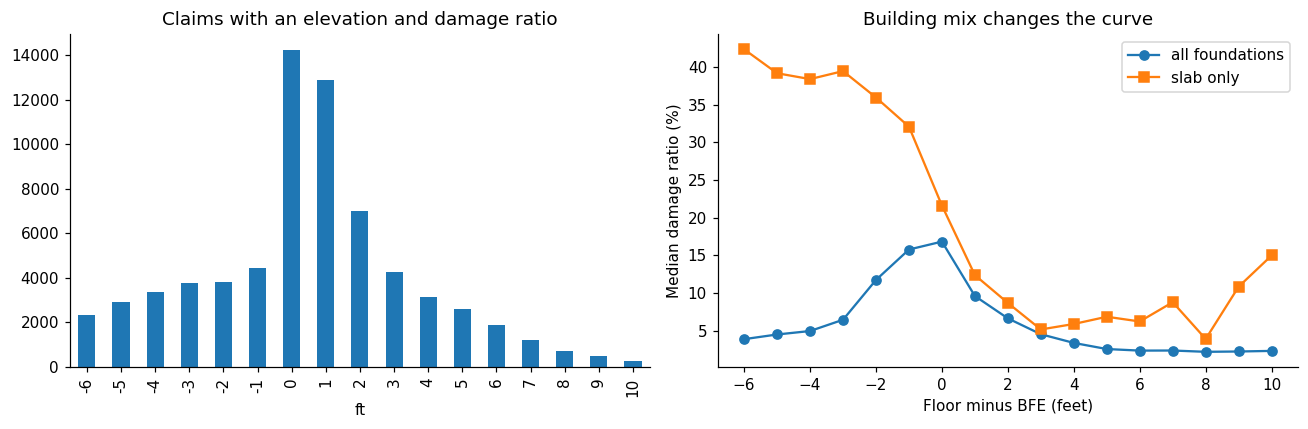

In [3]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
curve.claims.plot.bar(ax=ax[0],title='Claims with an elevation and damage ratio')
curve.median_ratio.mul(100).plot(ax=ax[1],marker='o',label='all foundations')
d[d.foundation=='1'].groupby('ft').damage_ratio.median().mul(100).plot(ax=ax[1],marker='s',label='slab only')
ax[1].set(xlabel='Floor minus BFE (feet)',ylabel='Median damage ratio (%)',title='Building mix changes the curve');ax[1].legend()
plt.tight_layout();plt.show()

### Step 3 · Check the mix rather than forcing an explanation
The table shows whether the low-floor groups contain different building types.

In [4]:
display(pd.crosstab(pd.cut(d.ft,[-7,-3,0,2,10]),d.foundation_name,normalize='index').round(2))

foundation_name,basement,crawlspace,elevated (4),elevated (5),elevated (6),not recorded,slab
ft,,,,,,,
"(-7, -3]",0.080,0.090,0.010,0.270,0.210,0.080,0.240
"(-3, 0]",0.020,0.100,0.040,0.060,0.040,0.080,0.660
"(0, 2]",0.010,0.060,0.110,0.060,0.040,0.080,0.630
"(2, 10]",0.010,0.050,0.260,0.240,0.190,0.090,0.170


## 2. Compare buildings above BFE
We compare 0 to +8 feet within zone AE and within the three largest events. These comparisons reduce some differences, but they do not match buildings at the same local water depth.

In [5]:
up=d[d.ft.between(0,8)].copy()
rows=[]
for name,g in [('all',up),('zone AE slab',up[(up.zone=='AE')&(up.foundation=='1')])]+[(s,up[up.floodEvent==s]) for s in ['Hurricane Helene','Hurricane Ian','Hurricane Ida']]:
    a=g.loc[g.ft==0,'damage_ratio'];b=g.loc[g.ft==2,'damage_ratio']
    rows.append({'group':name,'claims at 0':len(a),'claims at 2':len(b),'median at 0':a.median(),'median at 2':b.median()})
display(pd.DataFrame(rows).set_index('group').round(3))

,claims at 0,claims at 2,median at 0,median at 2
group,,,,
all,14243,6990,0.168,0.066
zone AE slab,9541,2967,0.224,0.087
Hurricane Helene,1327,602,0.091,0.038
Hurricane Ian,6228,1943,0.209,0.079
Hurricane Ida,1715,870,0.340,0.082


### Step 4 · Quantify the simple association first
A one-variable regression gives a reference slope. We do not call that slope the benefit of raising a house. The next controls ask whether part of the slope reflects other differences.

In [6]:
from sklearn.linear_model import LinearRegression
naive=LinearRegression().fit(up[['ft']],up.damage_ratio)
print(f'Unadjusted association: {naive.coef_[0]*100:.2f} percentage points per foot')

Unadjusted association: -2.94 percentage points per foot


## 3. Adjusted association and external features
We fit a regularized linear model with floor height, building age, foundation, occupancy, zone, state and event. We then add rain and track exposure. This tests whether the height association remains after including broad storm conditions.

The coefficient is an average association over 0–8 feet. The curve can be nonlinear. It does not tell us how much damage would change if an owner raised a particular house.

### Step 5 · Add building/event controls, then external exposure
If the coefficient changes, some of the simple association was mixed with measured differences. The remaining coefficient can still be confounded.

In [7]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
up['storm']=up.floodEvent.fillna('unnamed-'+up.loss_year.astype(str))
base=['ft','building_age','zone','foundation','occupancy','state','storm']
models={};coef_rows=[]
for name,cc in [('building + event',base),('plus rain + track',base+['rain_5d_mm','trk_dist_km','trk_wind_kt'])]:
    pre=prepare(up[cc]);XX=pre.fit_transform(up[cc]);names=pre.get_feature_names_out()
    j=list(names).index('number__ft')
    model=Ridge(alpha=10).fit(XX,up.damage_ratio)
    models[name]=(pre,XX,j,model)
    coef_rows.append({'features':name,'points per foot':model.coef_[j]*100})
display(pd.DataFrame(coef_rows).set_index('features').round(3))
pre,XX,j,model=models['plus rain + track']

,points per foot
features,
building + event,-1.459
plus rain + track,-1.467


## 4. Uncertainty and storm sensitivity
Claims in the same neighborhood and event may be related. We resample whole event–neighborhood groups, keeping their claims together. This interval is conditional on the observed storms. It does not capture every common effect across a hurricane.

We also remove each major storm in turn and compare slab buildings only. These checks are more useful than treating a narrow interval as proof of a causal effect.

### Step 6 · Resample related claims together
We estimate uncertainty conditional on the observed storms.

In [8]:
rng=np.random.default_rng(SEED);boot=[]
groups=neighborhood_groups(up)
for _ in range(300):
    ix=cluster_bootstrap_indices(groups,rng)
    boot.append(Ridge(alpha=10).fit(XX[ix],up.damage_ratio.iloc[ix]).coef_[j]*100)
lo,hi=np.percentile(boot,[2.5,97.5])
print(f'Event–neighborhood bootstrap 95% interval: {lo:.2f} to {hi:.2f} points per foot (300 draws)')

Event–neighborhood bootstrap 95% interval: -1.72 to -1.20 points per foot (300 draws)


### Step 7 · Remove a major storm and change the building subset
A narrow interval is not enough if the answer depends on one event or foundation type.

In [9]:
sensitivity=[]
for name,mask in [('all',np.ones(len(up),dtype=bool)),('slab only',up.foundation.eq('1').to_numpy())]+[(f'without {s}',up.floodEvent.ne(s).to_numpy()) for s in ['Hurricane Helene','Hurricane Ian','Hurricane Ida']]:
    mm=Ridge(alpha=10).fit(XX[mask],up.damage_ratio.iloc[np.flatnonzero(mask)])
    sensitivity.append({'sample':name,'claims':mask.sum(),'points per foot':mm.coef_[j]*100})
display(pd.DataFrame(sensitivity).set_index('sample').round(3))
save_table(pd.DataFrame(sensitivity).set_index('sample'),'06_height_sensitivity')

,claims,points per foot
sample,,
all,47996,-1.467
slab only,25480,-1.936
without Hurricane Helene,41885,-1.688
without Hurricane Ian,31979,-1.276
without Hurricane Ida,42206,-1.264


## 5. Answer and limits
**Answer.** Among claims with a recorded elevation, each extra foot of floor height goes with about 1.5 percentage points less damage (as a share of building value), after we control for building type, storm and place. The estimate stays negative when we drop any one big storm or look at slab buildings only.

**What we cannot say.** This is a comparison of different buildings, not an experiment. We do not know the real water depth, how well each house was built, or what raising it would cost. So we do not turn the number into dollars saved. Only claims appear in the data: houses that stayed dry are missing. Only about one third of claims have an elevation record, and that share changes by year.

### Decision ledger
We discarded the mixed overall curve as a causal explanation. We kept foundation-specific and event-specific comparisons, then added measured controls. We also discarded a dollar “return on elevation” calculation: the data lack actual flood depth, the probability of flooding, dry buildings and construction costs.

### Result in plain English

With the listed building, event, rain and track controls, one extra foot is associated with **1.47 percentage points lower damage ratio** in the selected sample. The storm-removal and slab-only checks show how the estimate changes with the sample. The association remains a comparison between different claims. It is not a measured dollar return from raising a house, because local water conditions and buildings that stayed dry are missing.